# Active learning: uncertain samples versus random samples

This notebook reads the recorded `active-learning-20261025` experiment. It needs only Python and matplotlib; it does not train, download data or use a GPU. Dataset images and weights remain outside Git.

The initial set contains 558 images (10% per class of the 5,583-image training split). A seed classifier ranks the other 5,025 training images by lowest maximum softmax probability. The uncertainty arm adds 200 images; the random control adds 200 with acquisition seed 43. Both retrain from the same pretrained initialization with training seed 42. Validation (986) and test (715) remain unchanged. Test evaluation runs only after all three models have been selected by validation loss.

**Labels are simulated using the public dataset's existing labels.** This measures acquisition strategy, not human annotation quality or time.


In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "docs/results/active-learning-20261025.json").is_file())
result = json.loads((root / "docs/results/active-learning-20261025.json").read_text())
acquisition = json.loads((root / "docs/results/active-learning-acquisition-20261025.json").read_text())
print("Source manifest:", result["protocol"]["source_manifest_sha256"])
print("Training seed:", result["protocol"]["seed"])
print("Shared acquired images:", result["acquisition_overlap"], "of 200")
print("Arm          Labels  Test accuracy  Macro F1  Training seconds  Best epoch")
for name in ("seed", "uncertainty", "random"):
    arm = result["arms"][name]
    print(f'{name:12} {arm["training_images"]:6}  {arm["metrics"]["accuracy"]:13.6f}  {arm["metrics"]["macro_f1"]:.6f}  {arm["training_seconds"]:16.1f}  {arm["run"]["best_epoch"]:10}')


Source manifest: fbce28e2e462ad9ccd0e046a4cbbef1dca7535ea710efa1eccfc0bf4f7bc7865
Training seed: 42
Shared acquired images: 11 of 200
Arm          Labels  Test accuracy  Macro F1  Training seconds  Best epoch
seed            558       0.997203  0.996993             192.0          16
uncertainty     758       0.997203  0.996993             168.3          12
random          758       0.997203  0.996993             196.5          16


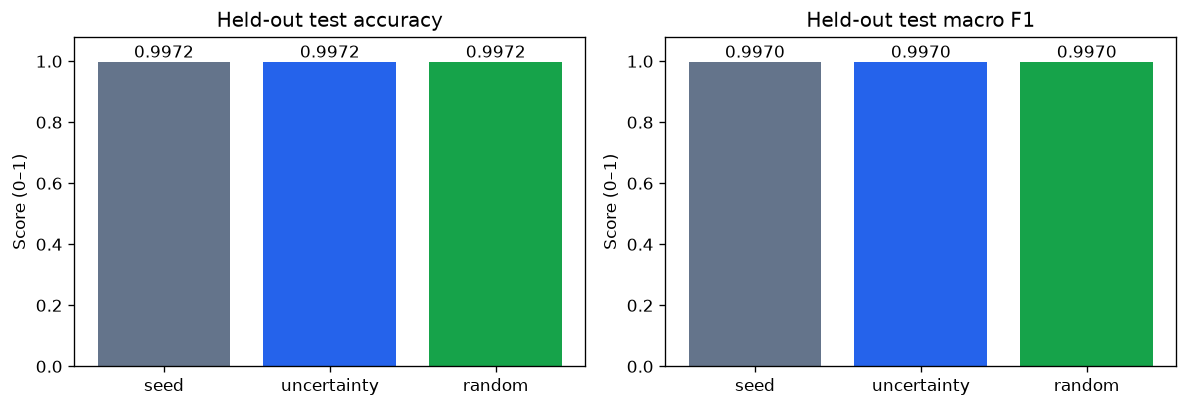

In [2]:
names = ["seed", "uncertainty", "random"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, metric, title in zip(axes, ["accuracy", "macro_f1"], ["Held-out test accuracy", "Held-out test macro F1"]):
    values = [result["arms"][name]["metrics"][metric] for name in names]
    ax.bar(names, values, color=["#64748b", "#2563eb", "#16a34a"])
    ax.set_ylim(0, 1.08)
    ax.set_title(title)
    ax.set_ylabel("Score (0–1)")
    for index, value in enumerate(values): ax.text(index, value + .015, f"{value:.4f}", ha="center")
fig.tight_layout()


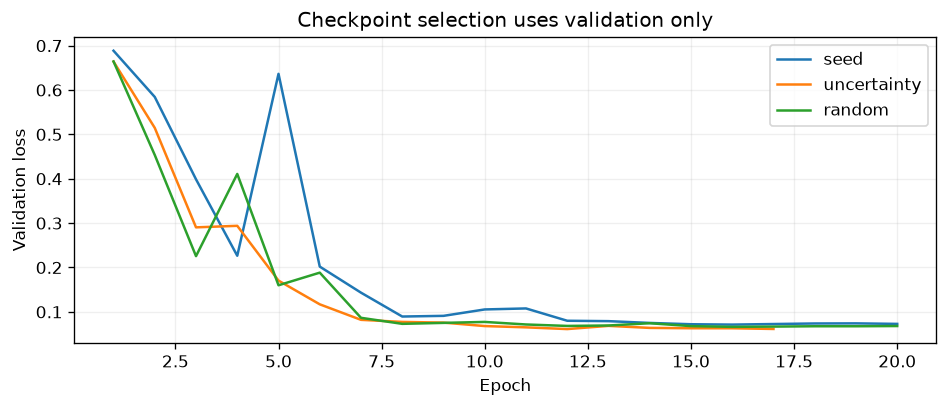

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for name in names:
    history = result["arms"][name]["history"]
    ax.plot([r["epoch"] for r in history], [r["val"]["loss"] for r in history], label=name)
ax.set(xlabel="Epoch", ylabel="Validation loss", title="Checkpoint selection uses validation only")
ax.legend(); ax.grid(alpha=.2); fig.tight_layout()


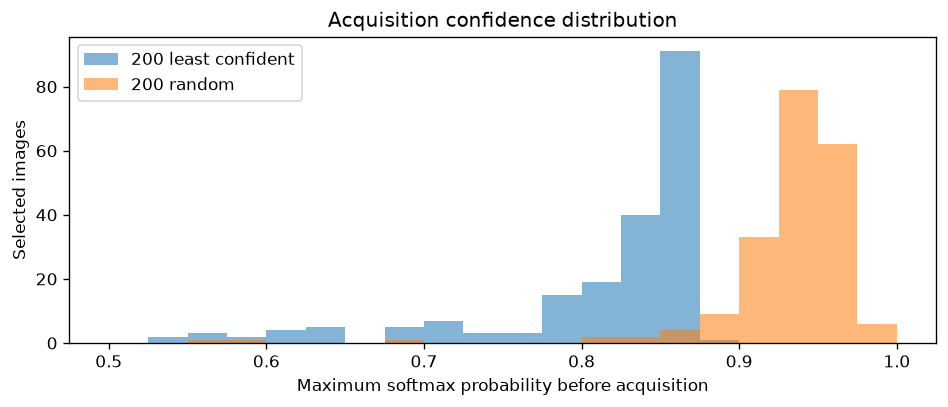

In [4]:
ranked = acquisition["ranked_pool"]
uncertain = set(acquisition["uncertainty_keys"])
random = set(acquisition["random_keys"])
assert uncertain == {r["image_key"] for r in ranked[:200]}
assert len(uncertain) == len(random) == 200
assert len({r["image_key"] for r in ranked}) == 5025
fig, ax = plt.subplots(figsize=(8, 3.5))
for keys, label in [(uncertain, "200 least confident"), (random, "200 random")]:
    ax.hist([r["confidence"] for r in ranked if r["image_key"] in keys], bins=20, range=(.5,1), alpha=.55, label=label)
ax.set(xlabel="Maximum softmax probability before acquisition", ylabel="Selected images", title="Acquisition confidence distribution")
ax.legend(); fig.tight_layout()


## What happened

All three arms scored **713/715 correct (99.7203%)**, with **macro F1 0.996993**. Adding 200 uncertain labels gave **0.0000 percentage points** of accuracy gain over random acquisition or the initial model. All three confusion matrices are `[[262, 0], [2, 451]]` (rows true, columns predicted; class order `ok`, `defective`). The acquired sets share 11 images.

This is a single-seed comparison near the accuracy ceiling. It does not establish that uncertainty sampling is generally better, worse or equivalent. Different loss/probability scores do not change the observed accuracy/F1 tie. No settings were changed after seeing the test results.

Training took approximately 192 seconds for the seed, 168 for uncertainty and 196 for random on one RTX A6000, excluding acquisition/evaluation/setup. The script limits the CUDA allocator to 20% of device memory. These are observed durations, not a performance guarantee.

## Reproduce

Run `python -m scripts.active_learning --manifest data/manifests/casting-v2/manifest.json --audit data/manifests/casting-v2/report.json --data-dir data --cache-dir MODEL_CACHE --output NEW_RUN_DIRECTORY` in the pinned training environment. Use an allocated CUDA device through `CUDA_VISIBLE_DEVICES`. Each output directory is immutable and must not already exist. `--device cpu` is supported but slower.

The committed result contains the experiment-script hash, checkpoint/report/manifest hashes, training configuration, histories and test reports. The acquisition snapshot contains all pool confidences and the two selected sets. The original audited source manifest is checked before training, and pixel groups cannot cross splits.
